###Workforce Demand and Employment Growth Analysis Using the U.S. National Employment Matrix

This project uses the U.S. Bureau of Labor Statistics (BLS) National Employment Matrix to analyze employment patterns across occupations and industries. The dataset contains occupational-industry employment estimates and projections for 2025 and 2035, along with percentage distributions and projected employment changes. The analysis aims to identify occupations and industries with significant employment growth, decline, and workforce demand.

Source :- https://www.bls.gov/emp/data/occupational-data.htm

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import files

uploaded = files.upload()

Saving matrix.xlsx to matrix.xlsx


In [6]:
import pandas as pd

df = pd.read_excel("matrix.xlsx")

In [7]:
df.head()

,Occupation type,Industry type,Occupation code,Occupation title,Industry code,Industry title,2025 Employment,2025 Percent of Industry,2025 Percent of Occupation,2035 Employment,2035 Percent of Industry,2035 Percent of Occupation,"Numeric change, 2025-35","Percent change, 2025-35"
0,Summary,Summary,00-0000,"Total, all occupations",TE1000,"Total, all industries",170280.8,100.0,100.0,176198.5,100.0,100.0,5917.6,3.5
1,Summary,Summary,11-0000,Management occupations,TE1000,"Total, all industries",13683.4,8.0,100.0,14527.6,8.2,100.0,844.2,6.2
2,Summary,Summary,11-1000,Top executives,TE1000,"Total, all industries",3904.1,2.3,100.0,4095.2,2.3,100.0,191.1,4.9
3,Line item,Summary,11-1011,Chief executives,TE1000,"Total, all industries",291.6,0.2,100.0,300.9,0.2,100.0,9.3,3.2
4,Line item,Summary,11-1021,General and operations managers,TE1000,"Total, all industries",3599.0,2.1,100.0,3780.3,2.1,100.0,181.3,5.0


In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 113898
Number of columns: 14


Data Cleaning

In [9]:
# Preserve the original dataset and create a working copy
df_raw = df.copy()
df_clean = df.copy()

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (113898, 14)
Working dataset shape: (113898, 14)


In [10]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
    .str.replace(r"[^a-z0-9_]", "", regex=True)
)

print(df_clean.columns.tolist())

['occupation_type', 'industry_type', 'occupation_code', 'occupation_title', 'industry_code', 'industry_title', '2025_employment', '2025_percent_of_industry', '2025_percent_of_occupation', '2035_employment', '2035_percent_of_industry', '2035_percent_of_occupation', 'numeric_change_202535', 'percent_change_202535']


The 14 column names were standardized into lowercase snake_case format

In [11]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113898 entries, 0 to 113897
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   occupation_type             113898 non-null  object 
 1   industry_type               113898 non-null  object 
 2   occupation_code             113898 non-null  object 
 3   occupation_title            113898 non-null  object 
 4   industry_code               113898 non-null  object 
 5   industry_title              113898 non-null  object 
 6   2025_employment             113898 non-null  float64
 7   2025_percent_of_industry    113898 non-null  float64
 8   2025_percent_of_occupation  113898 non-null  float64
 9   2035_employment             113898 non-null  float64
 10  2035_percent_of_industry    113898 non-null  float64
 11  2035_percent_of_occupation  113898 non-null  float64
 12  numeric_change_202535       113898 non-null  float64
 13  percent_change

The dataset contained six text columns and eight numerical columns. All columns had 113,898 non-null values, and their data types were suitable for the initial analysis.

In [12]:
print(df_clean.isnull().sum())
print("\nTotal missing values:", df_clean.isnull().sum().sum())

occupation_type               0
industry_type                 0
occupation_code               0
occupation_title              0
industry_code                 0
industry_title                0
2025_employment               0
2025_percent_of_industry      0
2025_percent_of_occupation    0
2035_employment               0
2035_percent_of_industry      0
2035_percent_of_occupation    0
numeric_change_202535         0
percent_change_202535         0
dtype: int64

Total missing values: 0



No missing values were detected in any column. Therefore, no missing-value imputation or row removal was required.

In [13]:
print("Complete duplicate rows:", df_clean.duplicated().sum())

print(
    "Repeated occupation-industry combinations:",
    df_clean.duplicated(
        subset=["occupation_code", "industry_code"],
        keep=False
    ).sum()
)

Complete duplicate rows: 0
Repeated occupation-industry combinations: 0


In [14]:
for column in df_clean.select_dtypes(include="object").columns:
    df_clean[column] = df_clean[column].str.strip()

for column in ["occupation_type", "industry_type"]:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))


occupation_type:
occupation_type
Line item    67816
Summary      46082
Name: count, dtype: int64

industry_type:
industry_type
Line item    61029
Summary      52869
Name: count, dtype: int64


The occupation and industry classifications contained the categories Line item and Summary. These categories were retained because they represent different levels of detail. Leading and trailing whitespace was removed from text columns.

In [15]:
# Check negative employment estimates
for column in ["2025_employment", "2035_employment"]:
    print(column, "negative values:", (df_clean[column] < 0).sum())

# Check percentage values outside 0–100
percentage_columns = [
    "2025_percent_of_industry",
    "2025_percent_of_occupation",
    "2035_percent_of_industry",
    "2035_percent_of_occupation"
]

for column in percentage_columns:
    invalid_count = (
        (df_clean[column] < 0) |
        (df_clean[column] > 100)
    ).sum()
    print(column, "invalid values:", invalid_count)

# Check infinite values
numeric_df = df_clean.select_dtypes(include=np.number)
print("Infinite values:", np.isinf(numeric_df).sum().sum())

2025_employment negative values: 0
2035_employment negative values: 0
2025_percent_of_industry invalid values: 0
2025_percent_of_occupation invalid values: 0
2035_percent_of_industry invalid values: 0
2035_percent_of_occupation invalid values: 0
Infinite values: 0


No negative employment estimates, infinite values, or percentage values outside the 0–100 range were identified.



In [16]:
iqr_columns = [
    "2025_employment",
    "2035_employment",
    "numeric_change_202535",
    "percent_change_202535"
]

outlier_results = []

for column in iqr_columns:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower,
        "Upper bound": upper,
        "Potential outliers": count
    })

display(pd.DataFrame(outlier_results).round(2))

,Column,Q1,Q3,IQR,Lower bound,Upper bound,Potential outliers
0,2025_employment,0.2,4.9,4.7,-6.85,11.95,17912
1,2035_employment,0.2,5.0,4.8,-7.00,12.20,17913
2,numeric_change_202535,0.0,0.1,0.1,-0.15,0.25,30649
3,percent_change_202535,-1.9,6.7,8.6,-14.80,19.60,7886


The IQR method flagged 17,912 observations in 2025 employment, 17,913 in 2035 employment, 30,649 in numerical employment change, and 7,886 in percentage employment change.

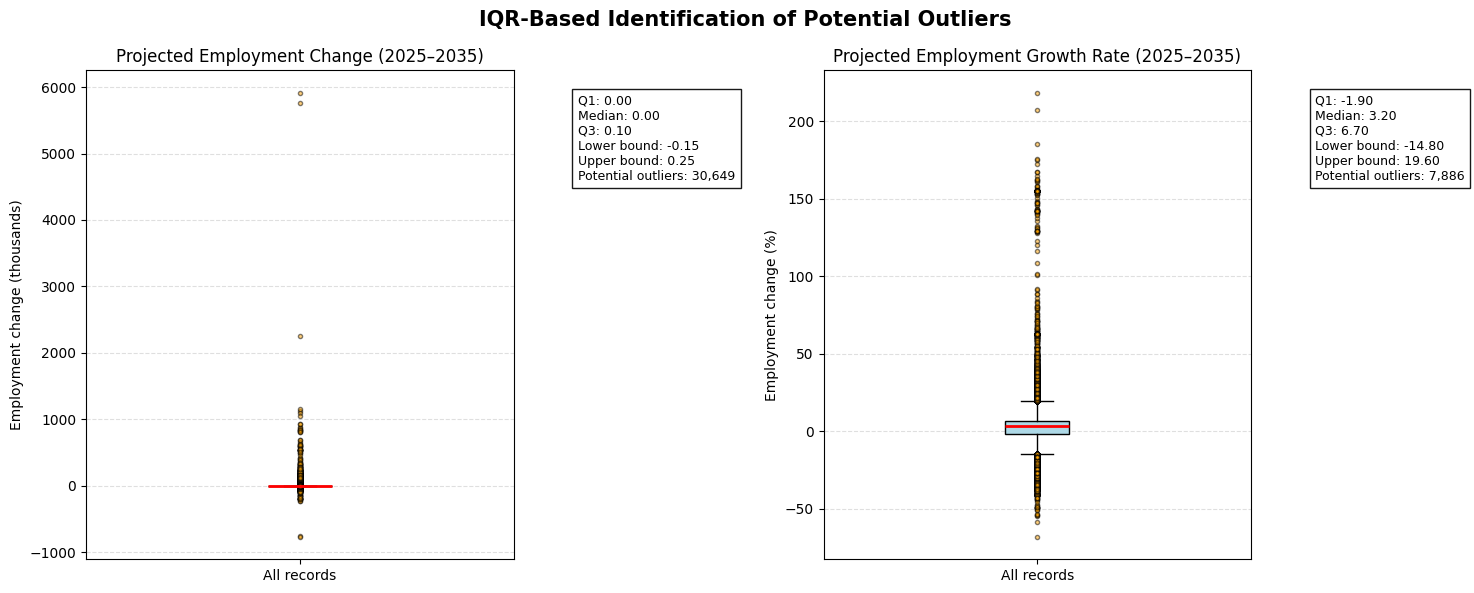

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Variables to analyse
columns = [
    "numeric_change_202535",
    "percent_change_202535"
]

titles = [
    "Projected Employment Change (2025–2035)",
    "Projected Employment Growth Rate (2025–2035)"
]

units = [
    "Employment change (thousands)",
    "Employment change (%)"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, column, title, unit in zip(axes, columns, titles, units):

    data = df_clean[column].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[(data < lower) | (data > upper)]

    ax.boxplot(
        data,
        vert=True,
        patch_artist=True,
        boxprops=dict(facecolor="lightblue"),
        medianprops=dict(color="red", linewidth=2),
        flierprops=dict(
            marker="o",
            markerfacecolor="orange",
            markersize=3,
            alpha=0.5
        )
    )

    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.set_xticks([1])
    ax.set_xticklabels(["All records"])
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Display actual numerical results
    stats = (
        f"Q1: {q1:.2f}\n"
        f"Median: {data.median():.2f}\n"
        f"Q3: {q3:.2f}\n"
        f"Lower bound: {lower:.2f}\n"
        f"Upper bound: {upper:.2f}\n"
        f"Potential outliers: {len(outliers):,}"
    )

    ax.text(
        1.15, 0.95, stats,
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.9)
    )

plt.suptitle(
    "IQR-Based Identification of Potential Outliers",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


The IQR method identified several potential statistical outliers in employment changes and projected growth rates. However, these observations were retained because unusually large employment changes may reflect genuine differences in workforce demand across occupations and industries. Since the dataset includes both aggregate and detailed employment records, variations in employment size are expected. Therefore, the identified outliers were not automatically considered data errors or removed from the analysis.

In [19]:
# Compare reported and independently calculated employment change

df_clean["calculated_employment_change"] = (
    df_clean["2035_employment"] -
    df_clean["2025_employment"]
)

df_clean["change_difference"] = (
    df_clean["numeric_change_202535"] -
    df_clean["calculated_employment_change"]
)

print(
    "Maximum absolute difference:",
    df_clean["change_difference"].abs().max()
)

print(
    "Rows with differences greater than 0.01:",
    (df_clean["change_difference"].abs() > 0.01).sum()
)

# Inspect records with the largest differences
display(
    df_clean.loc[
        df_clean["change_difference"].abs() > 0.01,
        [
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "calculated_employment_change",
            "change_difference"
        ]
    ].head(10)
)

Maximum absolute difference: 0.10000000001127773
Rows with differences greater than 0.01: 22982


,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,calculated_employment_change,change_difference
0,"Total, all occupations","Total, all industries",170280.8,176198.5,5917.6,5917.7,-0.1
6,Advertising and promotions managers,"Total, all industries",33.2,31.9,-1.2,-1.3,0.1
7,Marketing and sales managers,"Total, all industries",1071.7,1129.9,58.1,58.2,-0.1
8,Marketing managers,"Total, all industries",421.6,450.8,29.1,29.2,-0.1
15,Administrative services managers,"Total, all industries",279.0,293.3,14.4,14.3,0.1
24,Training and development managers,"Total, all industries",50.2,53.5,3.2,3.3,-0.1
28,Education and childcare administrators,"Total, all industries",729.6,730.6,1.1,1.0,0.1
30,"Education administrators, kindergarten through...","Total, all industries",343.8,342.7,-1.2,-1.1,-0.1
35,Entertainment and recreation managers,"Total, all industries",49.4,52.3,2.8,2.9,-0.1
37,"Entertainment and recreation managers, except ...","Total, all industries",43.9,46.5,2.7,2.6,0.1


The reported employment changes were compared with independently calculated changes. A maximum absolute difference of approximately 0.1 was found, with 22,982 records differing by more than 0.01.



In [20]:
date_columns = df_clean.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

print("Date columns:", date_columns)

Date columns: []


In [21]:
df_clean["calculated_employment_change"] = (
    df_clean["2035_employment"] -
    df_clean["2025_employment"]
)

display(
    df_clean[
        [
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "calculated_employment_change"
        ]
    ].head()
)

,2025_employment,2035_employment,numeric_change_202535,calculated_employment_change
0,170280.8,176198.5,5917.6,5917.7
1,13683.4,14527.6,844.2,844.2
2,3904.1,4095.2,191.1,191.1
3,291.6,300.9,9.3,9.3
4,3599.0,3780.3,181.3,181.3


A new column, calculated_employment_change, was created by subtracting 2025 employment from 2035 employment. It was used to compare the calculated changes with the values reported in the source dataset.

In [22]:
# Final data-quality summary

quality_report = pd.DataFrame({
    "Data Quality Check": [
        "Number of rows",
       "Original number of columns",
        "Missing values",
        "Complete duplicate rows",
        "Infinite numerical values",
        "Negative 2025 employment values",
        "Negative 2035 employment values",
        "Date columns"
    ],
    "Result": [
        df_clean.shape[0],
        df_raw.shape[1],
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        int(np.isinf(
            df_clean.select_dtypes(include=np.number)
        ).sum().sum()),
        int((df_clean["2025_employment"] < 0).sum()),
        int((df_clean["2035_employment"] < 0).sum()),
        len(date_columns)
    ]
})

display(quality_report)

,Data Quality Check,Result
0,Number of rows,113898
1,Original number of columns,14
2,Missing values,0
3,Complete duplicate rows,0
4,Infinite numerical values,0
5,Negative 2025 employment values,0
6,Negative 2035 employment values,0
7,Date columns,0


The final data-quality report confirmed 113,898 rows and 14 original columns, with no missing values, complete duplicate rows, infinite values, or negative employment estimates. Potential outliers and small employment-change discrepancies were documented for further interpretation.

In [23]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=quality_report)

https://docs.google.com/spreadsheets/d/1pSBdNJKqKby-jxd1uuDMzj-OJ98Bfq7VzK-0IBkWpuM/edit#gid=0


In [24]:
# Save the preprocessed working dataset
df_clean.to_csv(
    "cleaned_national_employment_matrix.csv",
    index=False
)

print("Preprocessed dataset saved successfully.")
print("Dataset shape:", df_clean.shape)

Preprocessed dataset saved successfully.
Dataset shape: (113898, 16)


In [25]:
from google.colab import files

files.download("cleaned_national_employment_matrix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Two additional columns, calculated_employment_change and change_difference, were added to compare independently calculated employment changes with the source-reported values. Small discrepancies were identified, and the original source values were preserved.

The final exported working dataset contained 113,898 rows and 16 columns.

#Rechecking Text Consistency and Duplicate Records
After standardizing text values by removing leading and trailing whitespace, the dataset was checked again for completely duplicated rows and repeated occupation–industry code combinations. This verification ensured that the standardization process had not created duplicate records.

In [26]:
# Check for remaining leading/trailing spaces
text_columns = df_clean.select_dtypes(include="object").columns

space_check = {
    column: int(
        df_clean[column].ne(df_clean[column].str.strip()).sum()
    )
    for column in text_columns
}

print("Values with extra spaces:", space_check)

# Recheck complete duplicate rows
print(
    "\nComplete duplicate rows:",
    df_clean.duplicated().sum()
)

# Recheck occupation-industry code combinations
print(
    "Repeated occupation-industry combinations:",
    df_clean.duplicated(
        subset=["occupation_code", "industry_code"],
        keep=False
    ).sum()
)

Values with extra spaces: {'occupation_type': 0, 'industry_type': 0, 'occupation_code': 0, 'occupation_title': 0, 'industry_code': 0, 'industry_title': 0}

Complete duplicate rows: 0
Repeated occupation-industry combinations: 0


Separating Summary and Line Item Records

The dataset contains both Summary and Line item records. These classifications were separated to support appropriate comparisons and avoid mixing aggregated employment values with detailed occupation–industry records. The original dataset was retained, and the separate subsets were created for validation and subsequent analysis.

In [27]:
#Check Summary and Line item records separately

print("Occupation type counts:")
print(df_clean["occupation_type"].value_counts())

print("\nIndustry type counts:")
print(df_clean["industry_type"].value_counts())

print("\nOccupation type × Industry type:")
print(
    df_clean.groupby(["occupation_type", "industry_type"])
    .size()
    .unstack(fill_value=0)
)

Occupation type counts:
occupation_type
Line item    67816
Summary      46082
Name: count, dtype: int64

Industry type counts:
industry_type
Line item    61029
Summary      52869
Name: count, dtype: int64

Occupation type × Industry type:
industry_type    Line item  Summary
occupation_type                    
Line item            34474    33342
Summary              26555    19527


The dataset was examined using the occupation_type and industry_type columns. The occupation type contained 67,816 Line item records and 46,082 Summary records, while the industry type contained 61,029 Line item records and 52,869 Summary records. A cross-tabulation was performed to examine their combinations. The results showed that the dataset includes both detailed and summary-level records. These categories will be considered separately during subsequent analysis to reduce the risk of mixing aggregated figures with detailed employment data.

#Validating Employment Change and Percentage Change

The source-reported numerical employment change and percentage change were compared with independently calculated values. The calculated employment change was obtained by subtracting 2025 employment from 2035 employment. Percentage change was calculated relative to 2025 employment, where the baseline was greater than zero.

Negative changes were retained because they may indicate projected employment declines. Differences were investigated before determining whether they resulted from rounding or other inconsistencies.

In [28]:
# Step 3: Examine employment changes and percentage changes

columns_to_check = [
    "numeric_change_202535",
    "percent_change_202535"
]

for column in columns_to_check:
    print(f"\n{column}")
    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())
    print("Negative values:", (df_clean[column] < 0).sum())
    print("Zero values:", (df_clean[column] == 0).sum())
    print("Positive values:", (df_clean[column] > 0).sum())
    print("Missing values:", df_clean[column].isna().sum())


numeric_change_202535
Minimum: -772.4
Maximum: 5917.6
Negative values: 16173
Zero values: 59212
Positive values: 38513
Missing values: 0

percent_change_202535
Minimum: -68.3
Maximum: 218.4
Negative values: 35404
Zero values: 649
Positive values: 77845
Missing values: 0


The employment change and percentage change columns were examined to identify their minimum and maximum values, negative, zero and positive values, and missing values. The numeric employment change ranged from -772.4 to 5,917.6, while the percentage change ranged from -68.3% to 218.4%. Both columns contained negative and positive values, reflecting potential employment declines and increases. No missing values were found. Negative changes and large percentage increases were retained for further investigation because they are not necessarily data errors.

In [29]:
# Inspect the largest and smallest percentage changes

columns_to_display = [
    "occupation_type",
    "industry_type",
    "occupation_code",
    "occupation_title",
    "industry_code",
    "industry_title",
    "2025_employment",
    "2035_employment",
    "numeric_change_202535",
    "percent_change_202535"
]

print("Top 10 highest percentage changes:")
display(
    df_clean.nlargest(10, "percent_change_202535")[columns_to_display]
)

print("\nTop 10 lowest percentage changes:")
display(
    df_clean.nsmallest(10, "percent_change_202535")[columns_to_display]
)

Top 10 highest percentage changes:


,occupation_type,industry_type,occupation_code,occupation_title,industry_code,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
7482,Line item,Line item,15-2051,Data scientists,221114,Solar electric power generation,0.1,0.2,0.1,218.4
7481,Summary,Line item,15-2000,Mathematical science occupations,221114,Solar electric power generation,0.1,0.2,0.2,207.4
7465,Line item,Line item,13-1081,Logisticians,221114,Solar electric power generation,0.1,0.2,0.1,185.3
7496,Summary,Line item,19-0000,"Life, physical, and social science occupations",221114,Solar electric power generation,0.1,0.2,0.2,175.6
7491,Line item,Line item,17-2141,Mechanical engineers,221114,Solar electric power generation,0.1,0.3,0.2,175.1
7452,Line item,Line item,11-3021,Computer and information systems managers,221114,Solar electric power generation,0.1,0.2,0.1,172.5
7455,Line item,Line item,11-9021,Construction managers,221114,Solar electric power generation,0.4,1.1,0.7,167.4
7460,Line item,Line item,13-1020,Buyers and purchasing agents,221114,Solar electric power generation,0.1,0.4,0.2,167.4
7453,Line item,Line item,11-3031,Financial managers,221114,Solar electric power generation,0.4,1.2,0.7,164.9
7490,Line item,Line item,17-2071,Electrical engineers,221114,Solar electric power generation,0.5,1.2,0.7,162.4



Top 10 lowest percentage changes:


,occupation_type,industry_type,occupation_code,occupation_title,industry_code,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
1679,Line item,Line item,43-3041,Gambling cage workers,TE1100,Self-employed workers,0.3,0.1,-0.2,-68.3
1225,Line item,Line item,17-2011,Aerospace engineers,TE1100,Self-employed workers,0.1,0.0,-0.1,-58.6
1637,Line item,Line item,39-9041,Residential advisors,TE1100,Self-employed workers,2.8,1.3,-1.5,-54.4
18053,Summary,Line item,43-9020,Data entry and information processing workers,315000,Apparel manufacturing,0.1,0.0,0.0,-54.3
18054,Line item,Line item,43-9021,Data entry keyers,315000,Apparel manufacturing,0.1,0.0,0.0,-54.3
53126,Line item,Line item,43-9022,Word processors and typists,513110,Newspaper publishers,0.1,0.1,-0.1,-53.6
52949,Line item,Summary,43-9022,Word processors and typists,513100,"Newspaper, Periodical, Book, and Directory Pub...",0.2,0.1,-0.1,-51.0
52718,Line item,Summary,43-9022,Word processors and typists,5136A9,"Miscellaneous information services (5131, 516,...",0.2,0.1,-0.1,-50.8
1380,Summary,Line item,25-2030,Secondary school teachers,TE1100,Self-employed workers,1.3,0.7,-0.7,-49.8
1381,Line item,Line item,25-2031,"Secondary school teachers, except special and ...",TE1100,Self-employed workers,1.3,0.6,-0.6,-49.8


The records with the highest and lowest percentage changes were examined alongside their occupation, industry, and employment values. The highest reported percentage change was 218.4%, while the lowest was -68.3%. Several records had small employment values, indicating that large percentage changes may occur even when the absolute employment change is relatively small. Negative percentage changes were retained because they may represent genuine projected employment declines. These extreme records were flagged for further investigation rather than removed automatically.

In [30]:
# Compare reported and calculated employment changes

calculated_change = (
    df_clean["2035_employment"] - df_clean["2025_employment"]
)

difference = (
    df_clean["numeric_change_202535"] - calculated_change
)

print("Maximum absolute difference:", difference.abs().max())
print(
    "Records with differences greater than 0.01:",
    (difference.abs() > 0.01).sum()
)

# Display the records with the largest differences
comparison = df_clean[
    [
        "occupation_type",
        "industry_type",
        "occupation_code",
        "occupation_title",
        "industry_code",
        "industry_title",
        "2025_employment",
        "2035_employment",
        "numeric_change_202535"
    ]
].copy()

comparison["calculated_change"] = calculated_change
comparison["difference"] = difference

display(
    comparison.loc[difference.abs().nlargest(10).index]
)

Maximum absolute difference: 0.10000000001127773
Records with differences greater than 0.01: 22982


,occupation_type,industry_type,occupation_code,occupation_title,industry_code,industry_title,2025_employment,2035_employment,numeric_change_202535,calculated_change,difference
0,Summary,Summary,00-0000,"Total, all occupations",TE1000,"Total, all industries",170280.8,176198.5,5917.6,5917.7,-0.1
84229,Summary,Summary,29-0000,Healthcare practitioners and technical occupat...,620000,Healthcare and social assistance,7835.1,8521.8,686.8,686.7,0.1
675,Summary,Summary,43-0000,Office and administrative support occupations,TE1000,"Total, all industries",18792.7,18040.5,-752.1,-752.2,0.1
1099,Summary,Summary,53-7060,Laborers and material movers,TE1000,"Total, all industries",6761.4,7047.1,285.6,285.7,-0.1
2842,Summary,Summary,49-0000,"Installation, maintenance, and repair occupations",TE1200,Total wage and salary employment,6193.2,6546.6,353.3,353.4,-0.1
103228,Summary,Summary,00-0000,"Total, all occupations",810000,Other services (except public administration),6575.7,6822.6,246.8,246.9,-0.1
410,Summary,Summary,29-0000,Healthcare practitioners and technical occupat...,TE1000,"Total, all industries",10232.8,11052.4,819.5,819.6,-0.1
556,Summary,Summary,35-0000,Food preparation and serving related occupations,TE1000,"Total, all industries",13826.5,14429.1,602.5,602.6,-0.1
647,Summary,Summary,41-2010,Cashiers,TE1000,"Total, all industries",3128.3,2927.2,-201.0,-201.1,0.1
905,Summary,Summary,51-0000,Production occupations,TE1000,"Total, all industries",8780.5,8747.1,-33.5,-33.4,-0.1


The source-reported employment changes were compared with changes calculated by subtracting 2025 employment from 2035 employment. The maximum absolute difference was approximately 0.1, and 22,982 records had differences greater than 0.01. The displayed differences were small, but their exact cause could not be confirmed from the available results. Rounding of the displayed employment estimates may contribute to these discrepancies. The original reported values were retained, and calculated changes were kept separately for comparison.

In [31]:
#Validate occupation and industry codes

code_columns = ["occupation_code", "industry_code"]

for column in code_columns:
    codes = df_clean[column].astype("string")

    print(f"\n{column}")
    print("Missing codes:", codes.isna().sum())
    print("Blank codes:", codes.str.strip().eq("").sum())
    print(
        "Codes with extra spaces:",
        codes.ne(codes.str.strip()).fillna(False).sum()
    )
    print("Unique codes:", codes.nunique())
    print("Sample codes:")
    print(codes.dropna().drop_duplicates().head(10).to_list())


occupation_code
Missing codes: 0
Blank codes: 0
Codes with extra spaces: 0
Unique codes: 1112
Sample codes:
['00-0000', '11-0000', '11-1000', '11-1011', '11-1021', '11-2000', '11-2011', '11-2020', '11-2021', '11-2022']

industry_code
Missing codes: 0
Blank codes: 0
Codes with extra spaces: 0
Unique codes: 423
Sample codes:
['TE1000', 'TE1100', 'TE1200', '110000', '111000', '112000', '113000', '1131-2', '113300', '114000']


The occupation and industry code columns were checked for missing values, blank entries, extra spaces, and unique values. No missing codes, blank codes, or extra spaces were identified. The dataset contained 1,112 unique occupation codes and 423 unique industry codes. Since the codes contain letters, hyphens, and digits, they were retained as text to preserve their original formats. This check confirmed basic consistency but did not independently verify every code against the official classification system.

In [32]:
# Final data-quality validation

import numpy as np
import pandas as pd

print("Dataset shape:", df_clean.shape)

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nMissing values:", df_clean.isna().sum().sum())
print("Complete duplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes.value_counts())

numeric_df = df_clean.select_dtypes(include="number")

print(
    "\nInfinite values:",
    np.isinf(numeric_df.to_numpy()).sum()
)

print("\nMissing values by column:")
print(df_clean.isna().sum())

print("\nData types by column:")
print(df_clean.dtypes)

Dataset shape: (113898, 16)

Column names:
['occupation_type', 'industry_type', 'occupation_code', 'occupation_title', 'industry_code', 'industry_title', '2025_employment', '2025_percent_of_industry', '2025_percent_of_occupation', '2035_employment', '2035_percent_of_industry', '2035_percent_of_occupation', 'numeric_change_202535', 'percent_change_202535', 'calculated_employment_change', 'change_difference']

Missing values: 0
Complete duplicate rows: 0

Data types:
float64    10
object      6
Name: count, dtype: int64

Infinite values: 0

Missing values by column:
occupation_type                 0
industry_type                   0
occupation_code                 0
occupation_title                0
industry_code                   0
industry_title                  0
2025_employment                 0
2025_percent_of_industry        0
2025_percent_of_occupation      0
2035_employment                 0
2035_percent_of_industry        0
2035_percent_of_occupation      0
numeric_change_202535

The cleaned dataset was subjected to final validation checks. It contained 113,898 rows and 16 columns, including 14 original columns and two derived columns created during the analysis. No missing values, complete duplicate rows, or infinite numeric values were found. The results confirmed that the dataset passed these basic structural quality checks.

In [33]:
# Generate the final data-quality report

quality_report = pd.DataFrame({
    "Check": [
        "Total rows",
        "Total columns",
        "Missing values",
        "Complete duplicate rows",
        "Infinite numeric values",
        "Text columns",
        "Numeric columns",
        "Negative 2025 employment values",
        "Negative 2035 employment values"
    ],
    "Result": [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isna().sum().sum(),
        df_clean.duplicated().sum(),
        np.isinf(
            df_clean.select_dtypes(include="number").to_numpy()
        ).sum(),
        len(df_clean.select_dtypes(include="object").columns),
        len(df_clean.select_dtypes(include="number").columns),
        (df_clean["2025_employment"] < 0).sum(),
        (df_clean["2035_employment"] < 0).sum()
    ]
})

display(quality_report)

,Check,Result
0,Total rows,113898
1,Total columns,16
2,Missing values,0
3,Complete duplicate rows,0
4,Infinite numeric values,0
5,Text columns,6
6,Numeric columns,10
7,Negative 2025 employment values,0
8,Negative 2035 employment values,0


In [34]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=quality_report)

https://docs.google.com/spreadsheets/d/1ULAIxoMuhBdxJAn-WEaMHqFnwGarvIsdGyrr74rOxaY/edit#gid=0


The final data-quality report confirmed that the dataset contained 113,898 rows and 16 columns. No missing values, complete duplicate rows, infinite numeric values, or negative employment values were detected for 2025 or 2035. The dataset consisted of six text columns and ten numeric columns. These results indicate that the dataset passed the structural validation checks performed during preprocessing. The findings do not independently establish the validity of every source value or derived calculation.

In [35]:
# Step 1: Validate reported and calculated percentage changes

baseline = df_clean["2025_employment"]

# Calculate percentage change only when 2025 employment is positive
calculated_pct = (
    (
        df_clean["2035_employment"] - baseline
    ) / baseline.where(baseline > 0)
) * 100

# Compare source-reported and calculated percentages
pct_difference = (
    df_clean["percent_change_202535"] - calculated_pct
)

print(
    "Records with zero 2025 employment:",
    (baseline == 0).sum()
)

print(
    "Records with undefined calculated percentage:",
    calculated_pct.isna().sum()
)

print(
    "Maximum absolute percentage difference:",
    pct_difference.abs().max()
)

print(
    "Records differing by more than 0.1 percentage points:",
    (pct_difference.abs() > 0.1).sum()
)

# Inspect the records with the largest differences
pct_comparison = df_clean[
    [
        "occupation_type",
        "industry_type",
        "occupation_title",
        "industry_title",
        "2025_employment",
        "2035_employment",
        "percent_change_202535"
    ]
].copy()

pct_comparison["calculated_percent_change"] = calculated_pct
pct_comparison["percent_change_difference"] = pct_difference

display(
    pct_comparison.loc[
        pct_difference.abs().nlargest(10).index
    ]
)

Records with zero 2025 employment: 0
Records with undefined calculated percentage: 0
Maximum absolute percentage difference: 154.7
Records differing by more than 0.1 percentage points: 99061


,occupation_type,industry_type,occupation_title,industry_title,2025_employment,2035_employment,percent_change_202535,calculated_percent_change,percent_change_difference
7543,Summary,Line item,Supervisors of production workers,Solar electric power generation,0.1,0.1,154.7,0.0,154.7
7544,Line item,Line item,First-line supervisors of production and opera...,Solar electric power generation,0.1,0.1,154.7,0.0,154.7
7502,Summary,Line item,"Arts, design, entertainment, sports, and media...",Solar electric power generation,0.1,0.1,147.7,0.0,147.7
7478,Summary,Line item,"Software and web developers, programmers, and ...",Solar electric power generation,0.1,0.4,152.7,300.0,-147.3
7462,Summary,Line item,Human resources workers,Solar electric power generation,0.1,0.4,154.7,300.0,-145.3
7463,Line item,Line item,Human resources specialists,Solar electric power generation,0.1,0.4,154.7,300.0,-145.3
7467,Line item,Line item,Management analysts,Solar electric power generation,0.1,0.4,154.7,300.0,-145.3
7534,Line item,Line item,Helpers--electricians,Solar electric power generation,0.1,0.1,142.0,0.0,142.0
6847,Line item,Summary,"Title examiners, abstractors, and searchers",Electric power generation,0.1,0.1,135.4,0.0,135.4
7460,Line item,Line item,Buyers and purchasing agents,Solar electric power generation,0.1,0.4,167.4,300.0,-132.6


In [36]:
# Inspect the precision of employment values

pd.set_option("display.precision", 10)

display(
    df_clean[
        [
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "percent_change_202535"
        ]
    ].loc[[7543, 7544, 7502, 7478, 7462]]
)

,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
7543,Supervisors of production workers,Solar electric power generation,0.1,0.1,0.1,154.7
7544,First-line supervisors of production and opera...,Solar electric power generation,0.1,0.1,0.1,154.7
7502,"Arts, design, entertainment, sports, and media...",Solar electric power generation,0.1,0.1,0.1,147.7
7478,"Software and web developers, programmers, and ...",Solar electric power generation,0.1,0.4,0.2,152.7
7462,Human resources workers,Solar electric power generation,0.1,0.4,0.2,154.7


In [37]:
# Check the available sheets in the original Excel workbook

excel_file = pd.ExcelFile("matrix.xlsx")

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Matrix', 'Field Descriptions']


In [38]:
# Load and inspect the field descriptions sheet

field_descriptions = pd.read_excel(
    "matrix.xlsx",
    sheet_name="Field Descriptions"
)

display(field_descriptions)

,2025-35 National Employment Matrix,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Employment Projections Program,NaN,NaN
2,"Bureau of Labor Statistics, Department of Labor",NaN,NaN
3,website: https://www.bls.gov/emp,NaN,NaN
4,phone: 202-691-5700,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN
7,NaN,NaN,NaN
8,Field,Field Description,Format
9,Occupation type,Level of detail,text


In [39]:

# Compare source-reported percentage change
# with an approximate calculation using displayed values

calculated_pct_approx = (
    df_clean["numeric_change_202535"]
    / df_clean["2025_employment"].where(
        df_clean["2025_employment"] > 0
    )
) * 100

pct_difference_approx = (
    df_clean["percent_change_202535"]
    - calculated_pct_approx
)

print("Records compared:", pct_difference_approx.notna().sum())

print(
    "Records differing by more than 0.1 percentage points:",
    (pct_difference_approx.abs() > 0.1).sum()
)

print(
    "Maximum absolute difference:",
    pct_difference_approx.abs().max()
)

# Display sample records
comparison = df_clean.loc[
    [7543, 7544, 7502, 7478, 7462],
    [
        "occupation_title",
        "2025_employment",
        "2035_employment",
        "numeric_change_202535",
        "percent_change_202535"
    ]
].copy()

comparison["approx_calculated_percentage"] = (
    calculated_pct_approx.loc[comparison.index]
)

comparison["percentage_difference"] = (
    pct_difference_approx.loc[comparison.index]
)

display(comparison.round(2))

Records compared: 113898
Records differing by more than 0.1 percentage points: 97798
Maximum absolute difference: 118.4


,occupation_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535,approx_calculated_percentage,percentage_difference
7543,Supervisors of production workers,0.1,0.1,0.1,154.7,100.0,54.7
7544,First-line supervisors of production and opera...,0.1,0.1,0.1,154.7,100.0,54.7
7502,"Arts, design, entertainment, sports, and media...",0.1,0.1,0.1,147.7,100.0,47.7
7478,"Software and web developers, programmers, and ...",0.1,0.4,0.2,152.7,200.0,-47.3
7462,Human resources workers,0.1,0.4,0.2,154.7,200.0,-45.3


Validation of Source-Reported Percentage Changes
The source-reported percentage changes were compared with approximate percentages calculated using the displayed employment changes and 2025 employment values.

The comparison identified differences between the two sets of values. However, the employment estimates in the dataset are rounded to one decimal place (in thousands). Therefore, calculations using these displayed values may not reproduce the original percentage changes calculated from the underlying employment estimates.

According to the source documentation, employment data are rounded. Consequently, these differences should not automatically be interpreted as errors in the source data.

The original source-reported percentage changes were retained for the analysis. They were used to examine projected growth, alongside employment levels and absolute employment changes. The comparison is intended to assess consistency using the rounded published values, rather than to reproduce the exact underlying BLS calculations.

In [40]:
# Display the notes from the Field Descriptions sheet

display(
    field_descriptions.iloc[24:27]
)

,2025-35 National Employment Matrix,Unnamed: 1,Unnamed: 2
24,Notes:,NaN,NaN
25,1. Industry-occupation cells that are confiden...,NaN,NaN
26,2. Data for detailed occupations and industrie...,NaN,NaN


In [41]:
# Display the complete source notes without truncation

for i in [25, 26]:
    print(f"\nNote {i - 24}:")
    print(field_descriptions.iloc[i, 0])


Note 1:
1. Industry-occupation cells that are confidential, have poor statistical quality, or represent fewer than 50 jobs have been suppressed

Note 2:
2. Data for detailed occupations and industries may not sum to the totals for the summaries because summaries include data for occupations and industries which were suppressed and because employment data are rounded


In [42]:
# Check employment values below 50 jobs (0.05 thousand)

below_50_2025 = (df_clean["2025_employment"] < 0.05).sum()
below_50_2035 = (df_clean["2035_employment"] < 0.05).sum()

print("2025 employment values below 50 jobs:", below_50_2025)
print("2035 employment values below 50 jobs:", below_50_2035)

print(
    "Records below 50 jobs in either year:",
    (
        (df_clean["2025_employment"] < 0.05)
        | (df_clean["2035_employment"] < 0.05)
    ).sum()
)

2025 employment values below 50 jobs: 0
2035 employment values below 50 jobs: 530
Records below 50 jobs in either year: 530


In [43]:
# Summarize the distribution of source-reported percentage changes

display(
    df_clean["percent_change_202535"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)

,percent_change_202535
count,113898.0000000000
mean,2.6338653883
std,10.4249754537
min,-68.3000000000
1%,-24.9000000000
5%,-12.8000000000
25%,-1.9000000000
50%,3.2000000000
75%,6.7000000000
95%,16.1000000000


In [44]:
# Identify extreme percentage changes using the 1st and 99th percentiles

lower_limit = df_clean["percent_change_202535"].quantile(0.01)
upper_limit = df_clean["percent_change_202535"].quantile(0.99)

extreme_changes = df_clean[
    (df_clean["percent_change_202535"] < lower_limit)
    | (df_clean["percent_change_202535"] > upper_limit)
]

print("Lower threshold:", lower_limit)
print("Upper threshold:", upper_limit)
print("Records outside these thresholds:", len(extreme_changes))

# Inspect the 10 largest reported increases
display(
    df_clean.nlargest(10, "percent_change_202535")[
        [
            "occupation_type",
            "industry_type",
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "percent_change_202535"
        ]
    ]
)

Lower threshold: -24.9
Upper threshold: 28.0
Records outside these thresholds: 2268


,occupation_type,industry_type,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
7482,Line item,Line item,Data scientists,Solar electric power generation,0.1,0.2,0.1,218.4
7481,Summary,Line item,Mathematical science occupations,Solar electric power generation,0.1,0.2,0.2,207.4
7465,Line item,Line item,Logisticians,Solar electric power generation,0.1,0.2,0.1,185.3
7496,Summary,Line item,"Life, physical, and social science occupations",Solar electric power generation,0.1,0.2,0.2,175.6
7491,Line item,Line item,Mechanical engineers,Solar electric power generation,0.1,0.3,0.2,175.1
7452,Line item,Line item,Computer and information systems managers,Solar electric power generation,0.1,0.2,0.1,172.5
7455,Line item,Line item,Construction managers,Solar electric power generation,0.4,1.1,0.7,167.4
7460,Line item,Line item,Buyers and purchasing agents,Solar electric power generation,0.1,0.4,0.2,167.4
7453,Line item,Line item,Financial managers,Solar electric power generation,0.4,1.2,0.7,164.9
7490,Line item,Line item,Electrical engineers,Solar electric power generation,0.5,1.2,0.7,162.4


In [45]:
# Compare extreme percentage changes with absolute employment changes

extreme_changes = df_clean[
    (df_clean["percent_change_202535"] < lower_limit)
    | (df_clean["percent_change_202535"] > upper_limit)
].copy()

extreme_changes["absolute_employment_change"] = (
    extreme_changes["numeric_change_202535"].abs()
)

print(
    "Extreme percentage-change records:",
    len(extreme_changes)
)

print(
    "Extreme records with absolute employment change below 1,000 jobs:",
    (
        extreme_changes["absolute_employment_change"] < 1
    ).sum()
)

print(
    "Extreme records with absolute employment change below 10,000 jobs:",
    (
        extreme_changes["absolute_employment_change"] < 10
    ).sum()
)

# Inspect the largest percentage increases alongside employment changes
display(
    extreme_changes.nlargest(
        10, "percent_change_202535"
    )[
        [
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "percent_change_202535"
        ]
    ]
)

Extreme percentage-change records: 2268
Extreme records with absolute employment change below 1,000 jobs: 1784
Extreme records with absolute employment change below 10,000 jobs: 2183


,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
7482,Data scientists,Solar electric power generation,0.1,0.2,0.1,218.4
7481,Mathematical science occupations,Solar electric power generation,0.1,0.2,0.2,207.4
7465,Logisticians,Solar electric power generation,0.1,0.2,0.1,185.3
7496,"Life, physical, and social science occupations",Solar electric power generation,0.1,0.2,0.2,175.6
7491,Mechanical engineers,Solar electric power generation,0.1,0.3,0.2,175.1
7452,Computer and information systems managers,Solar electric power generation,0.1,0.2,0.1,172.5
7455,Construction managers,Solar electric power generation,0.4,1.1,0.7,167.4
7460,Buyers and purchasing agents,Solar electric power generation,0.1,0.4,0.2,167.4
7453,Financial managers,Solar electric power generation,0.4,1.2,0.7,164.9
7490,Electrical engineers,Solar electric power generation,0.5,1.2,0.7,162.4


Analysis of Extreme Employment Percentage Changes
The analysis identified 2,268 records with reported percentage changes below the 1st percentile or above the 99th percentile. Of these, 1,784 records had absolute employment changes below 1,000 jobs, while 2,183 had changes below 10,000 jobs. This indicates that extreme percentage changes frequently occur alongside relatively small absolute employment changes. Therefore, percentage growth should be interpreted alongside employment levels and numeric changes. The original source-reported values were retained for further analysis.

In [46]:
# Count summary and detailed records

print("Occupation type:")
display(df_clean["occupation_type"].value_counts())

print("\nIndustry type:")
display(df_clean["industry_type"].value_counts())

print("\nOccupation type and industry type:")
display(
    pd.crosstab(
        df_clean["occupation_type"],
        df_clean["industry_type"]
    )
)

Occupation type:


,count
occupation_type,
Line item,67816
Summary,46082



Industry type:


,count
industry_type,
Line item,61029
Summary,52869



Occupation type and industry type:


industry_type,Line item,Summary
occupation_type,,
Line item,34474,33342
Summary,26555,19527


In [47]:
# Create a subset containing detailed occupations and detailed industries

df_detailed = df_clean[
    (df_clean["occupation_type"] == "Line item")
    & (df_clean["industry_type"] == "Line item")
].copy()

print("Original dataset shape:", df_clean.shape)
print("Detailed-record subset shape:", df_detailed.shape)

print(
    "\nOccupation type values:",
    df_detailed["occupation_type"].unique()
)

print(
    "Industry type values:",
    df_detailed["industry_type"].unique()
)

Original dataset shape: (113898, 16)
Detailed-record subset shape: (34474, 16)

Occupation type values: ['Line item']
Industry type values: ['Line item']


Creating a Detailed-Record Subset
A separate subset, df_detailed, was created by filtering the cleaned dataset to include only records classified as Line item for both occupation type and industry type. The subset contains 34,474 rows and 16 columns, compared with 113,898 rows in the original cleaned dataset. This subset will be used for detailed occupation–industry analysis to reduce the risk of mixing detailed records with summary records. The original dataset was retained for broader analysis.

In [48]:
# Check duplicate occupation-industry combinations in the detailed subset

duplicate_pairs = df_detailed.duplicated(
    subset=["occupation_code", "industry_code"],
    keep=False
)

print(
    "Repeated occupation-industry code combinations:",
    duplicate_pairs.sum()
)

print(
    "Unique occupation-industry code combinations:",
    df_detailed[
        ["occupation_code", "industry_code"]
    ].drop_duplicates().shape[0]
)

Repeated occupation-industry code combinations: 0
Unique occupation-industry code combinations: 34474


#Duplicate Validation of Detailed Records
The detailed-record subset was checked for duplicate combinations of occupation code and industry code. No repeated combinations were identified. All 34,474 records had unique occupation–industry code combinations, confirming that each combination appears only once in this subset. This validation supports the structural consistency of the dataset for subsequent occupation–industry analysis.

In [50]:
# Identify the 10 largest projected employment increases

top_employment_increases = df_detailed.nlargest(
    10,
    "numeric_change_202535"
)

display(
    top_employment_increases[
        [
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "percent_change_202535"
        ]
    ]
)

,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
95302,Home health and personal care aides,Services for the elderly and persons with disa...,2368.5,2901.8,533.3,22.5
87714,Home health and personal care aides,Home healthcare services,1091.5,1294.4,202.9,18.6
39962,Stockers and order fillers,General merchandise retailers,862.1,978.2,116.1,13.5
39644,Stockers and order fillers,Grocery and specialty food retailers,657.7,770.3,112.6,17.1
102798,"Cooks, restaurant",Full-service restaurants,1062.0,1155.0,93.0,8.8
63606,Software developers,Computer systems design and related services,505.8,578.4,72.6,14.4
12642,Electricians,Electrical contractors and other wiring instal...,545.0,607.2,62.2,11.4
89860,Registered nurses,General medical and surgical hospitals; private,1644.2,1706.2,62.0,3.8
85335,Nurse practitioners,Offices of physicians,152.3,211.0,58.7,38.6
85407,Medical assistants,Offices of physicians,463.3,521.2,58.0,12.5


#Top Occupation–Industry Combinations by Projected Employment Increase
The top 10 occupation–industry combinations were identified using the source-reported numeric employment change for 2025–2035. Home health and personal care aides in services for the elderly and persons with disabilities recorded the largest projected increase, at 533.3 thousand jobs. Additional increases were observed in home healthcare services, retail, food services, software development, electrical contracting, and healthcare occupations.

The results indicate that projected workforce demand varies across industries and occupations. Absolute employment changes were examined alongside reported percentage changes to provide context for the scale of projected growth. These findings represent projections for specific occupation–industry combinations rather than economy-wide totals for each occupation.

In [51]:
# Identify the 10 highest reported percentage increases
# within detailed occupation-industry records

top_percentage_growth = df_detailed.nlargest(
    10,
    "percent_change_202535"
)

display(
    top_percentage_growth[
        [
            "occupation_title",
            "industry_title",
            "2025_employment",
            "2035_employment",
            "numeric_change_202535",
            "percent_change_202535"
        ]
    ]
)

,occupation_title,industry_title,2025_employment,2035_employment,numeric_change_202535,percent_change_202535
7482,Data scientists,Solar electric power generation,0.1,0.2,0.1,218.4
7465,Logisticians,Solar electric power generation,0.1,0.2,0.1,185.3
7491,Mechanical engineers,Solar electric power generation,0.1,0.3,0.2,175.1
7452,Computer and information systems managers,Solar electric power generation,0.1,0.2,0.1,172.5
7455,Construction managers,Solar electric power generation,0.4,1.1,0.7,167.4
7460,Buyers and purchasing agents,Solar electric power generation,0.1,0.4,0.2,167.4
7453,Financial managers,Solar electric power generation,0.4,1.2,0.7,164.9
7490,Electrical engineers,Solar electric power generation,0.5,1.2,0.7,162.4
7443,Chief executives,Solar electric power generation,0.1,0.2,0.1,154.7
7444,General and operations managers,Solar electric power generation,1.0,2.5,1.5,154.7


#Top Occupation–Industry Combinations by Reported Percentage Growth
The 10 occupation–industry combinations with the highest source-reported percentage changes were identified within the detailed-record subset. All 10 records were associated with Solar electric power generation. Data scientists recorded the highest reported increase at 218.4%, followed by logisticians at 185.3% and mechanical engineers at 175.1%.

These results differ from the ranking based on absolute employment increases. The occupations identified here have relatively small employment levels within this industry, illustrating why percentage growth should be interpreted alongside absolute employment change and baseline employment. The source-reported percentages were retained without modification.

In [52]:
# Rank industries by the sum of numeric employment changes
# across detailed occupation records


industry_growth = (
    df_detailed
    .groupby(
        ["industry_code", "industry_title"],
        as_index=False
    )
    .agg(
        total_2025_employment=("2025_employment", "sum"),
        total_2035_employment=("2035_employment", "sum"),
        total_numeric_change=("numeric_change_202535", "sum"),
        occupation_industry_records=("occupation_code", "count")
    )
    .sort_values(
        "total_numeric_change",
        ascending=False
    )
)

display(industry_growth.head(10))


,industry_code,industry_title,total_2025_employment,total_2035_employment,total_numeric_change,occupation_industry_records
253,624120,Services for the elderly and persons with disa...,2797.3,3422.2,623.8,167
236,621600,Home healthcare services,1806.7,2142.8,335.4,149
187,541500,Computer systems design and related services,2383.6,2694.9,310.6,196
188,541600,"Management, scientific, and technical consulti...",1837.2,2115.5,276.8,287
240,62210P,General medical and surgical hospitals; private,5148.6,5390.0,240.4,330
227,621100,Offices of physicians,2999.0,3210.7,211.4,244
271,722511,Full-service restaurants,5374.8,5538.9,164.7,71
290,TE1100,Self-employed workers,9821.8,9974.3,151.4,634
189,541710,"Research and development in the physical, engi...",833.0,973.3,138.4,292
232,621340,"Offices of physical, occupational and speech t...",511.7,640.7,128.9,126


#Industry-Level Analysis of Projected Employment Growth
Industries were ranked by summing the source-reported numeric employment changes across detailed occupation–industry records. Services for the elderly and persons with disabilities recorded the largest summed increase at 623.8 thousand jobs, followed by home healthcare services at 335.4 thousand and computer systems design and related services at 310.6 thousand.

The results highlight projected growth across care services, technology, consulting, healthcare, and research-related activities. These figures represent sums of detailed records rather than verified official industry totals. The source notes that suppression and rounding can cause detailed records to differ from summary totals.

In [53]:

# Interactive visualisation libraries

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Set the overall chart theme
pio.templates.default = "plotly_dark"

# Project colour palette
COLORS = {
    "navy": "#172554",
    "blue": "#3B82F6",
    "teal": "#14B8A6",
    "purple": "#A78BFA",
    "orange": "#F59E0B",
    "red": "#EF4444",
    "green": "#22C55E",
    "grey": "#94A3B8"
}

CHART_COLORS = [
    COLORS["teal"],
    COLORS["blue"],
    COLORS["purple"],
    COLORS["orange"],
    COLORS["green"],
    COLORS["red"]
]

print("Interactive visualisation environment is ready.")


Interactive visualisation environment is ready.


In [54]:

# 1. TOP 10 OCCUPATION-INDUSTRY COMBINATIONS
# BY PROJECTED EMPLOYMENT INCREASE

fig = px.bar(
    top_employment_increases.sort_values(
        "numeric_change_202535",
        ascending=True
    ),
    x="numeric_change_202535",
    y="occupation_title",
    color="numeric_change_202535",
    orientation="h",
    color_continuous_scale="Teal",
    hover_data={
        "industry_title": True,
        "2025_employment": ":.1f",
        "2035_employment": ":.1f",
        "numeric_change_202535": ":.1f",
        "percent_change_202535": ":.1f"
    },
    title="Top 10 Occupation–Industry Combinations by Employment Increase (2025–2035)",
    labels={
        "occupation_title": "Occupation",
        "numeric_change_202535": "Employment Change (thousands)",
        "industry_title": "Industry",
        "2025_employment": "2025 Employment (thousands)",
        "2035_employment": "2035 Employment (thousands)",
        "percent_change_202535": "Reported Change (%)"
    }
)

fig.update_layout(
    title_x=0.5,
    height=650,
    xaxis_title="Projected Employment Increase (thousands of jobs)",
    yaxis_title="Occupation",
    coloraxis_showscale=False,
    hoverlabel=dict(
        bgcolor="#172554",
        font_size=12
    )
)

fig.show()


### Interpretation: Top 10 Occupation–Industry Combinations by Employment Increase

The chart highlights the ten occupation–industry combinations with the largest projected employment increases between 2025 and 2035. Home health and personal care aides in services for the elderly and persons with disabilities recorded the highest increase, at **533.3 thousand jobs**. This was followed by stockers and order fillers in general merchandise retail, at **116.1 thousand jobs**, and home health and personal care aides in home healthcare services, at **202.9 thousand jobs**.

Other occupations showing notable projected increases include stockers and order fillers in grocery and specialty food retail, cooks in full-service restaurants, software developers, electricians, registered nurses, nurse practitioners, and medical assistants.

**Key finding:** The results highlight substantial projected employment growth in care-related services, retail, healthcare, technology, and skilled trades. Home health and personal care aides stand out across more than one industry, demonstrating that employment demand for the same occupation can vary by industry.

*Note: These values represent specific occupation–industry combinations, not total employment growth for each occupation across the entire economy.*

In [55]:

# TOP 10 RECORDS BY PERCENTAGE GROWTH


plot_data = top_percentage_growth.copy()

fig = px.scatter(
    plot_data,
    x="percent_change_202535",
    y="occupation_title",
    size="numeric_change_202535",
    color="numeric_change_202535",
    color_continuous_scale="Plasma",
    hover_name="occupation_title",
    hover_data={
        "industry_title": True,
        "2025_employment": ":.1f",
        "2035_employment": ":.1f",
        "numeric_change_202535": ":.1f",
        "percent_change_202535": ":.1f"
    },
    title="Top 10 Occupation–Industry Records by Reported Employment Growth (2025–2035)",
    labels={
        "occupation_title": "Occupation",
        "percent_change_202535": "Reported Employment Growth (%)",
        "numeric_change_202535": "Employment Change (thousands)",
        "industry_title": "Industry",
        "2025_employment": "2025 Employment (thousands)",
        "2035_employment": "2035 Employment (thousands)"
    },
    template="plotly_dark"
)

fig.update_traces(
    marker=dict(
        sizemin=10,
        line=dict(width=1, color="white")
    )
)

fig.update_layout(
    title_x=0.5,
    height=600,
    xaxis_title="Reported Employment Growth (%)",
    yaxis_title="Occupation",
    coloraxis_colorbar_title="Employment Change<br>(thousands)"
)

fig.show()


The chart shows that data scientists recorded the highest reported employment growth at 218.4%, followed by logisticians at 185.3% and mechanical engineers at 175.1%. Other occupations with high reported growth include computer and information systems managers, construction managers, buyers and purchasing agents, and financial managers. These findings highlight strong projected growth in technology, management, engineering, and logistics-related occupations. However, high percentage growth does not necessarily indicate the largest number of additional jobs, so it should be considered alongside absolute employment change.

In [56]:


# 3. INDUSTRY-LEVEL EMPLOYMENT GROWTH
# INTERACTIVE TREEMAP


# Create a separate copy to preserve the original analysis
industry_treemap_data = industry_growth.copy()

# Calculate growth rate using summed detailed employment values
industry_treemap_data = industry_treemap_data[
    industry_treemap_data["total_2025_employment"] > 0
].copy()

industry_treemap_data["calculated_growth_rate"] = (
    (
        industry_treemap_data["total_2035_employment"]
        - industry_treemap_data["total_2025_employment"]
    )
    / industry_treemap_data["total_2025_employment"]
) * 100

# Select the 15 industries with the largest positive increases
industry_treemap_data = (
    industry_treemap_data[
        industry_treemap_data["total_numeric_change"] > 0
    ]
    .nlargest(15, "total_numeric_change")
)

# Create interactive treemap
fig = px.treemap(
    industry_treemap_data,
    path=["industry_title"],
    values="total_numeric_change",
    color="calculated_growth_rate",
    color_continuous_scale="RdYlGn",
    hover_data={
        "total_2025_employment": ":.1f",
        "total_2035_employment": ":.1f",
        "total_numeric_change": ":.1f",
        "calculated_growth_rate": ":.2f",
        "occupation_industry_records": True
    },
    title="Top 15 Industries by Summed Employment Increase (2025–2035)",
    labels={
        "industry_title": "Industry",
        "total_numeric_change": "Summed Employment Increase (thousands)",
        "calculated_growth_rate": "Calculated Growth Rate (%)",
        "total_2025_employment": "Summed 2025 Employment (thousands)",
        "total_2035_employment": "Summed 2035 Employment (thousands)",
        "occupation_industry_records": "Detailed Records"
    }
)

fig.update_layout(
    title_x=0.5,
    height=750,
    coloraxis_colorbar_title="Growth Rate (%)"
)

fig.show()


In [57]:


# 4. COMPARISON OF EMPLOYMENT GAINS AND DECLINES


# Select the 10 largest increases and 10 largest declines
top_gains = df_detailed.nlargest(
    10, "numeric_change_202535"
).copy()

top_losses = df_detailed.nsmallest(
    10, "numeric_change_202535"
).copy()

# Combine both datasets
comparison_data = pd.concat(
    [top_gains, top_losses],
    ignore_index=True
)

# Create occupation-industry labels
comparison_data["chart_label"] = (
    comparison_data["occupation_title"]
    + " — "
    + comparison_data["industry_title"]
)

# Identify increase or decline
comparison_data["employment_status"] = np.where(
    comparison_data["numeric_change_202535"] >= 0,
    "Employment Increase",
    "Employment Decline"
)

# Sort for visual presentation
comparison_data = comparison_data.sort_values(
    "numeric_change_202535"
)

# Create interactive diverging chart
fig = px.bar(
    comparison_data,
    x="numeric_change_202535",
    y="chart_label",
    orientation="h",
    color="employment_status",
    color_discrete_map={
        "Employment Increase": COLORS["teal"],
        "Employment Decline": COLORS["red"]
    },
    hover_data={
        "2025_employment": ":.1f",
        "2035_employment": ":.1f",
        "numeric_change_202535": ":.1f",
        "percent_change_202535": ":.1f",
        "employment_status": True
    },
    title="Largest Projected Employment Gains and Declines (2025–2035)",
    labels={
        "chart_label": "Occupation–Industry Combination",
        "numeric_change_202535": "Employment Change (thousands)",
        "2025_employment": "2025 Employment (thousands)",
        "2035_employment": "2035 Employment (thousands)",
        "percent_change_202535": "Reported Change (%)",
        "employment_status": "Employment Trend"
    }
)

fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="white",
    line_width=1.5
)

fig.update_layout(
    title_x=0.5,
    height=900,
    xaxis_title="Projected Employment Change (thousands of jobs)",
    yaxis_title="Occupation–Industry Combination",
    legend_title="Employment Trend"
)

fig.show()


Interpretation: Projected Employment Gains and Declines
The chart compares the ten largest projected employment increases and declines across occupation–industry combinations. Home health and personal care aides in services for the elderly and persons with disabilities show the largest increase, while cashiers in grocery and specialty food retailers record the largest decline among the selected records. The results highlight that employment growth and decline are occurring across different occupations and industries, demonstrating that projected workforce demand is not uniform across the economy.

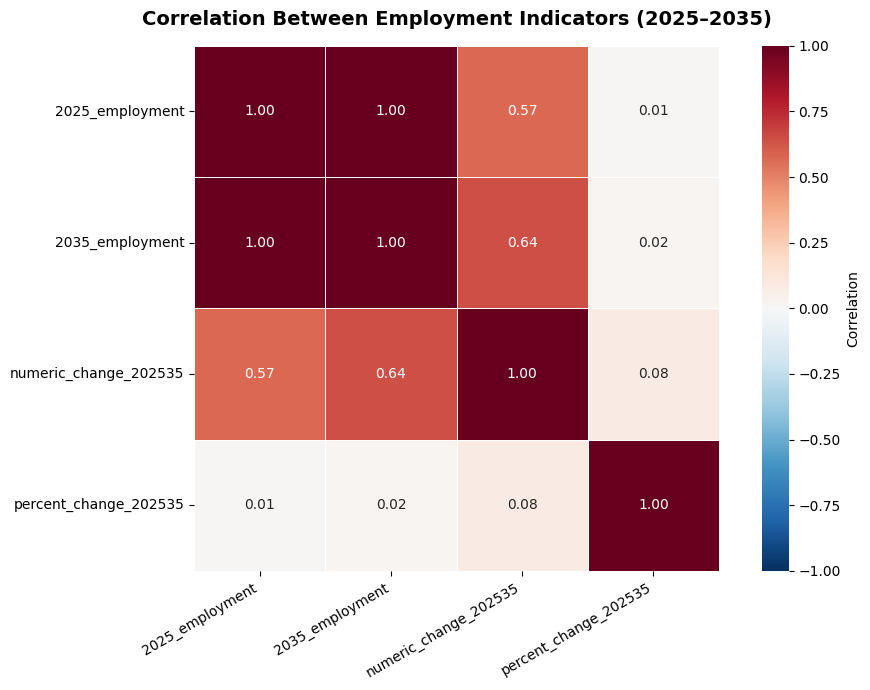

In [58]:


import matplotlib.pyplot as plt
import seaborn as sns

# Select employment indicators
correlation_data = df_detailed[
    [
        "2025_employment",
        "2035_employment",
        "numeric_change_202535",
        "percent_change_202535"
    ]
].copy()

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlation"}
)

plt.title(
    "Correlation Between Employment Indicators (2025–2035)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



#Interpretation: Correlation Between Employment Indicators
The heatmap shows a very strong positive correlation between 2025 and 2035 employment levels (1.00). Absolute employment change also has a moderate positive correlation with 2025 employment (0.57) and 2035 employment (0.64). In contrast, reported percentage change has very weak correlations with the other employment indicators. These results suggest that employment size and absolute job change are more closely related, while percentage growth provides a different perspective on projected employment patterns.

In [59]:

# 6. DISTRIBUTION OF EMPLOYMENT CHANGES


employment_changes = (
    df_detailed["numeric_change_202535"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Focus on the central 98% for readability
lower_limit, upper_limit = employment_changes.quantile([0.01, 0.99])

employment_focus = employment_changes[
    employment_changes.between(lower_limit, upper_limit)
]

fig = px.histogram(
    employment_focus,
    x=employment_focus,
    nbins=50,
    marginal="box",
    histnorm="probability density",
    color_discrete_sequence=[COLORS["teal"]],
    title="Distribution of Projected Employment Changes (2025–2035)",
    labels={
        "x": "Employment Change (thousands of jobs)",
        "y": "Probability Density"
    },
    template="plotly_dark"
)

fig.add_vline(
    x=0,
    line_dash="dash",
    line_color=COLORS["red"],
    line_width=2,
    annotation_text="Zero Change"
)

fig.update_layout(
    title_x=0.5,
    height=650,
    showlegend=False
)

fig.show()


The histogram shows that most occupation–industry records have employment changes concentrated close to zero, indicating relatively small projected changes for many records. The distribution is positively skewed, with a longer tail towards higher employment increases, while some records also show employment declines. This suggests that although many occupations experience modest changes, a smaller number are projected to have substantial employment growth or losses.

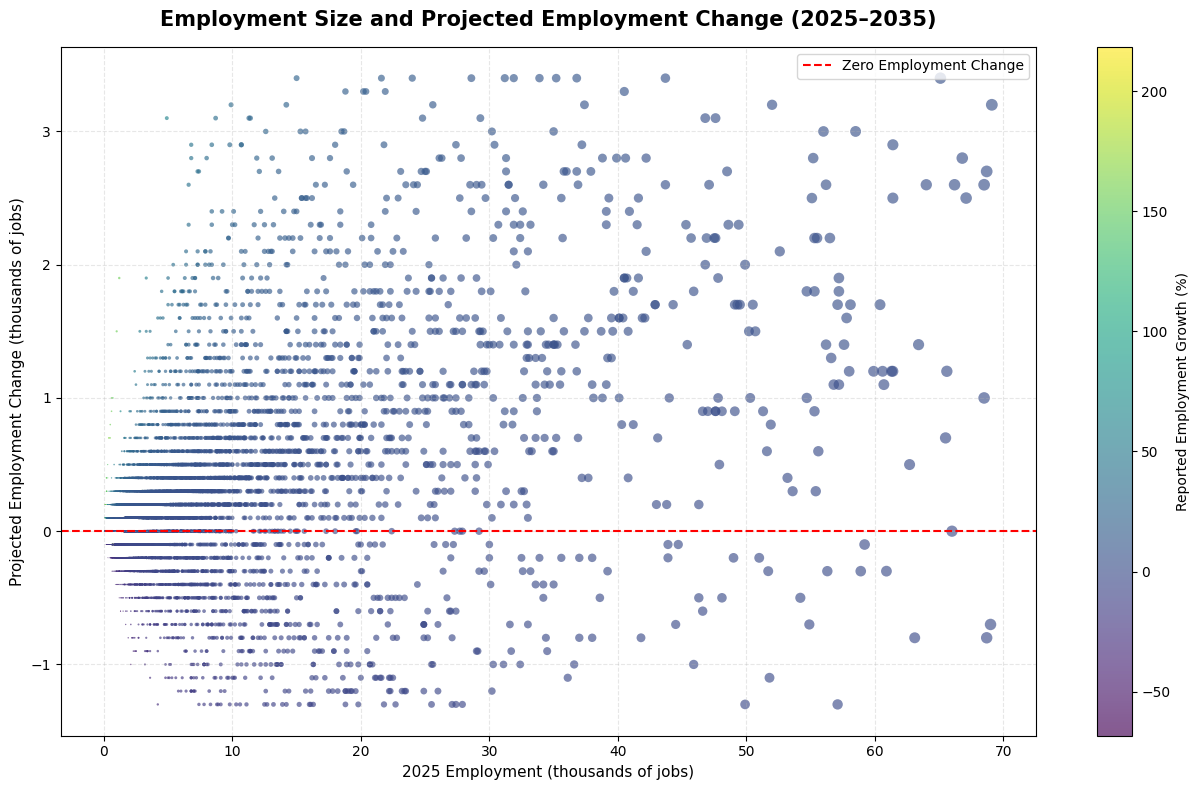

Records displayed: 33711
Extreme records excluded for visual clarity: 763


In [60]:

#EMPLOYMENT SIZE AND PROJECTED CHANGE
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

bubble_data = df_detailed.copy()

# Keep the central 98% of observations for visual clarity
x_low, x_high = bubble_data["2025_employment"].quantile([0.01, 0.99])
y_low, y_high = bubble_data["numeric_change_202535"].quantile([0.01, 0.99])

bubble_data = bubble_data[
    bubble_data["2025_employment"].between(x_low, x_high)
    & bubble_data["numeric_change_202535"].between(y_low, y_high)
].copy()

# Prepare bubble sizes
sizes = bubble_data["2035_employment"].clip(lower=0)

# Create figure
fig, ax = plt.subplots(figsize=(13, 8))

scatter = ax.scatter(
    bubble_data["2025_employment"],
    bubble_data["numeric_change_202535"],
    s=sizes,
    c=bubble_data["percent_change_202535"],
    cmap="viridis",
    alpha=0.65,
    edgecolors="none"
)

# Zero employment change reference line
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Zero Employment Change"
)

# Colour bar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Reported Employment Growth (%)")

# Titles and labels
ax.set_title(
    "Employment Size and Projected Employment Change (2025–2035)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("2025 Employment (thousands of jobs)", fontsize=11)
ax.set_ylabel("Projected Employment Change (thousands of jobs)", fontsize=11)

ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Display record counts
print("Records displayed:", len(bubble_data))
print(
    "Extreme records excluded for visual clarity:",
    len(df_detailed) - len(bubble_data)
)


This shows a wide variation in projected employment changes across occupation–industry records. Most records are concentrated at relatively lower 2025 employment levels, with many showing modest increases or decreases. Some records with higher starting employment also show substantial projected growth, while others show declines. The chart highlights that employment size and projected change do not follow a uniform pattern. A total of 33,711 records are displayed, with 763 extreme records excluded to improve visual clarity.

In [61]:

# 8. EMPLOYMENT COMPARISON: 2025 VS 2035
# INTERACTIVE DUMBBELL CHART


# Select the 10 largest occupation-industry combinations
dumbbell_data = (
    df_detailed
    .nlargest(10, "numeric_change_202535")
    .copy()
)

# Create readable occupation-industry labels
dumbbell_data["chart_label"] = (
    dumbbell_data["occupation_title"]
    + " — "
    + dumbbell_data["industry_title"]
)

# Sort records for presentation
dumbbell_data = dumbbell_data.sort_values(
    "numeric_change_202535",
    ascending=True
)

fig = go.Figure()

# Connecting lines between 2025 and 2035
for _, row in dumbbell_data.iterrows():
    fig.add_trace(
        go.Scatter(
            x=[row["2025_employment"], row["2035_employment"]],
            y=[row["chart_label"], row["chart_label"]],
            mode="lines",
            line=dict(
                color=COLORS["grey"],
                width=3
            ),
            showlegend=False,
            hoverinfo="skip"
        )
    )

# 2025 employment markers
fig.add_trace(
    go.Scatter(
        x=dumbbell_data["2025_employment"],
        y=dumbbell_data["chart_label"],
        mode="markers",
        name="2025 Employment",
        marker=dict(
            color=COLORS["blue"],
            size=13,
            line=dict(width=1, color="white")
        ),
        customdata=dumbbell_data[
            ["industry_title", "numeric_change_202535"]
        ],
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Industry: %{customdata[0]}<br>"
            "2025 Employment: %{x:.1f} thousand<br>"
            "Projected Change: %{customdata[1]:.1f} thousand"
            "<extra></extra>"
        )
    )
)

# 2035 employment markers
fig.add_trace(
    go.Scatter(
        x=dumbbell_data["2035_employment"],
        y=dumbbell_data["chart_label"],
        mode="markers",
        name="2035 Employment",
        marker=dict(
            color=COLORS["teal"],
            size=13,
            line=dict(width=1, color="white")
        ),
        customdata=dumbbell_data[
            ["industry_title", "numeric_change_202535"]
        ],
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Industry: %{customdata[0]}<br>"
            "2035 Employment: %{x:.1f} thousand<br>"
            "Projected Change: %{customdata[1]:.1f} thousand"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="Projected Employment Comparison: 2025 vs 2035",
    title_x=0.5,
    template="plotly_dark",
    height=750,
    xaxis_title="Employment (thousands of jobs)",
    yaxis_title="Occupation–Industry Combination",
    legend_title="Employment Year",
    hovermode="closest"
)

fig.show()


### Projected Employment Comparison (2025 vs 2035)

The chart shows an increase in projected employment across all ten selected occupation–industry combinations between 2025 and 2035. Home health and personal care aides in services for the elderly and persons with disabilities show the largest increase, followed by those in home healthcare services. Other occupations, including stockers and order fillers, software developers, electricians, and healthcare professionals, also show projected growth. Overall, the comparison highlights increasing employment demand across several care-related, retail, technology, and healthcare occupations.

In [63]:

# EXPORT BOTH DATASETS AS SEPARATE EXCEL FILES

from google.colab import files

# 1. Complete cleaned dataset
cleaned_file = "Final_Cleaned_National_Employment_Matrix.xlsx"

df_clean.to_excel(
    cleaned_file,
    sheet_name="Final Data Set",
    index=False
)

# 2. Detailed analysis dataset
detailed_file = "Detailed_Analysis_National_Employment_Matrix.xlsx"

df_detailed.to_excel(
    detailed_file,
    sheet_name="Detailed Analysis",
    index=False
)


# DATASET SUMMARY


print("FINAL DATASET EXPORT SUMMARY")
print("=" * 50)

print("\n1. COMPLETE CLEANED DATASET")
print("-" * 50)
print("File:", cleaned_file)
print("Rows:", f"{len(df_clean):,}")
print("Columns:", len(df_clean.columns))
print("Total cells:", f"{df_clean.size:,}")

print("\n2. DETAILED ANALYSIS DATASET")
print("-" * 50)
print("File:", detailed_file)
print("Rows:", f"{len(df_detailed):,}")
print("Columns:", len(df_detailed.columns))
print("Total cells:", f"{df_detailed.size:,}")

# Display column names
print("\nCOLUMN NAMES:")
for i, column in enumerate(df_clean.columns, start=1):
    print(f"{i}. {column}")


# DOWNLOAD FILES


print("\nDownloading complete cleaned dataset...")
files.download(cleaned_file)

print("\nDownloading detailed analysis dataset...")
files.download(detailed_file)


FINAL DATASET EXPORT SUMMARY

1. COMPLETE CLEANED DATASET
--------------------------------------------------
File: Final_Cleaned_National_Employment_Matrix.xlsx
Rows: 113,898
Columns: 16
Total cells: 1,822,368

2. DETAILED ANALYSIS DATASET
--------------------------------------------------
File: Detailed_Analysis_National_Employment_Matrix.xlsx
Rows: 34,474
Columns: 16
Total cells: 551,584

COLUMN NAMES:
1. occupation_type
2. industry_type
3. occupation_code
4. occupation_title
5. industry_code
6. industry_title
7. 2025_employment
8. 2025_percent_of_industry
9. 2025_percent_of_occupation
10. 2035_employment
11. 2035_percent_of_industry
12. 2035_percent_of_occupation
13. numeric_change_202535
14. percent_change_202535
15. calculated_employment_change
16. change_difference



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 📊 Project Summary
## Workforce Demand and Employment Growth Analysis Using the U.S. National Employment Matrix

### 🎯 1. Project Overview

This project examines projected employment patterns across U.S. occupations and industries between **2025 and 2035**, using the U.S. Bureau of Labor Statistics (BLS) National Employment Matrix.

The main objectives are to:

- Identify occupations and industries with significant projected employment growth and decline.
- Explore changes in workforce demand.
- Compare absolute employment changes with percentage growth.
- Examine relationships between employment levels and projected changes.
- Identify potential areas of future employment opportunities.

### 🧹 2. Data Preparation and Cleaning

The original dataset contained **113,898 records and 14 columns**.

The data preparation process included:

- Standardizing column names and cleaning text values.
- Examining missing values and duplicate records.
- Checking invalid employment estimates and percentage ranges.
- Identifying infinite numerical values.
- Creating two additional columns for employment change validation.

A detailed subset containing **34,474 occupation–industry records** was created by filtering records classified as `Line item` for both occupation and industry.

The final cleaned dataset contains:

- 113,898 records
- 16 columns
- 14 original columns
- 2 additional derived columns

### 📈 3. Key Findings

**🏥 Care-related services**

- Services for the elderly and persons with disabilities and home healthcare services showed substantial projected employment increases.
- Home health and personal care aides recorded the largest increase among the selected occupation–industry combinations, at **533.3 thousand jobs**.

**💻 Technology and professional occupations**

- Data scientists recorded the highest reported percentage growth among the selected records, at **218.4%**.
- Logisticians and mechanical engineers also demonstrated notable projected percentage growth.
- Software developers and computer systems-related services showed significant employment growth.

**⚡ Industry growth**

- Care services, computer systems design, healthcare, and consulting featured among the industries with substantial summed employment increases.
- Solar electric power generation showed a particularly high calculated percentage growth rate.

**📉 Employment declines**

- Certain occupation–industry combinations showed projected employment declines.
- This demonstrates that employment growth is not uniform across all occupations and industries.

**📊 Correlation analysis**

- 2025 and 2035 employment levels showed a very strong positive correlation of **1.00**.
- Absolute employment change had moderate positive correlations with 2025 employment (**0.57**) and 2035 employment (**0.64**).
- Reported percentage change showed very weak correlations with the other employment indicators.

### 📊 4. Interactive Data Visualisations

Eight interactive visualisations were developed using Plotly to explore and communicate the findings.

1. 📊 **Horizontal Bar Chart** – Top 10 occupation–industry combinations by projected employment increase.
2. 🔵 **Scatter Plot** – Top 10 records by reported percentage growth.
3. 🟩 **Treemap** – Top 15 industries by summed employment increase.
4. 📉 **Diverging Bar Chart** – Comparison of the largest projected employment gains and declines.
5. 🔥 **Correlation Heatmap** – Relationships between employment indicators.
6. 📊 **Histogram** – Distribution of projected employment changes.
7. 🫧 **Bubble Chart** – Relationship between employment size and projected employment change.
8. 🔗 **Dumbbell Chart** – Comparison of 2025 and 2035 employment levels.

The charts include interactive hover information, different visualisation styles, and a consistent dark colour theme to make the results easier to explore and compare.

### 🔍 5. Data Validation and Limitations

The validation process identified:

- No missing values.
- No complete duplicate records.
- No infinite numerical values.
- No negative employment estimates.
- No invalid percentage distributions outside the 0–100 range.

**Important considerations:**

- Small differences were observed between source-reported and independently calculated employment changes.
- Percentage-change comparisons also showed differences, which may be affected by rounding in published employment estimates.
- Original source-reported employment changes and percentages were retained.
- Industry-level results represent sums of detailed occupation–industry records and should not be interpreted as verified official industry-wide totals.
- Employment figures are projections, not guaranteed future outcomes.

### 🎯 6. Conclusion

The analysis highlights significant differences in projected employment growth across U.S. occupations and industries between 2025 and 2035. Care-related services, healthcare, technology, and selected professional occupations demonstrate notable growth potential, while certain occupation–industry combinations are projected to experience employment declines.

The findings also demonstrate that high percentage growth does not necessarily translate into the largest number of additional jobs. Both employment levels and absolute changes are important when evaluating future workforce demand.

Overall, the projections provide insight into potential changes in the U.S. employment landscape, helping identify emerging employment opportunities, areas of increasing workforce demand, and occupations that may face changing employment conditions.